# Т-Интенсив. Управление рисками
## Август 2026

## Часть 1. График линейности признака по WoE.

В этой части домашки мы познакомимся с одним из основных инструментов для анализа переменных в модели логистической регрессии - графиком линейности.

Кратко идею этого графика можно сформулировать так:
 - модель *линейной* регрессии корректно применять, если значение $y$ *линейно* связано со значением $x$. Иначе линрег не подходит для данной задачи и даст неверные результаты.
 - аналогичную проверку хочется сделать и для *логистической* регрессии. Но как проверить линейность, если таргет принимает всего два значения?
 - для этого необходимо преобразовать таргет: разбить признак на бакеты и в каждом бакете посчитать WoE
 - **линейность признака по WoE для логрега – аналог линейной связи признака и таргета для линрега**

Ниже пример признака с неплохой линейностью:

![example.png](attachment:example.png)

Нам нужно обратить внимание на 3 вещи:

**1. Фиолетовые точки с доверительными интервалами.**

Это WoE для каждого отдельного бакета. В идеале нам бы хотелось, чтобы **через эти точки можно было провести прямую линию** с небольшой погрешностью. Это и означает линейную взаимосвязь с таргетом.

**2. Синяя линия**

Попытка провести прямую линию через точки. Строится с помощью логистической регрессии на одной переменной. Затем предсказания переводятся в пространство WoE, отчего и получается прямая линия.

**3. Метрики в заголовке графика**

Метрики для признака:
 - roc auc, IV измеряют разделяющую способность переменной
 - $R^2$ измеряет *линейность взаимосвязи*. Признак считается линейным, если $R^2 \geq 0.95$

Далее напишем woe-line руками, чтобы в деталях разобраться, как он строится.

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import scipy.stats as sps
from typing import Union, Tuple

### Шаг 0: разбиение на бакеты

In [ ]:
def calc_buckets(x : Union[np.ndarray, pd.Series], n_buckets : int) -> np.ndarray:
    """Разбивает массив значений признака x на
    n_buckets бакетов"""

    x = pd.Series(x).reset_index(drop=True)
    buckets = x.rank(method="dense", pct=True) * n_buckets
    buckets = np.ceil(buckets) - 1   # np.floor дает другой результат для 5.0, 6.0 и т.д.
    buckets = np.array(buckets, dtype=np.int16)

    return buckets

In [ ]:
# протестируйте calc_buckets
df = pd.read_csv("logreg_hw_5.csv", index_col=0)

df['bucket_feature_1'] = calc_buckets(df['feature_1'], n_buckets= 10)

print(df[['feature_1', 'bucket_feature_1']].sample(5))
print()
print("Распределение объектов по бакетам:")
print(df['bucket_feature_1'].value_counts().sort_index())

       feature_1  bucket_feature_1
94604   1.462880                 8
13687   0.495916                 6
54654   0.747320                 6
84119   2.664691                 9
30336   2.757298                 9

Распределение объектов по бакетам:
bucket_feature_1
0    10000
1    10000
2    10000
3    10000
4    10000
5    10000
6    10000
7    10000
8    10000
9    10000
Name: count, dtype: int64


### Шаг 1: расчет WoE по бакетам (3 балла)

Пусть $x_i \in \{ 0, 1\}^n$

$x_i$ - это вектор, состоящий из значений таргета *в одном бакете* $i$.

Для бакета можно посчитать количество единиц $B_i$ (bads, выпавшие в дефолт) и количество нулей $G_i$ (goods).

$$
B_i = \sum_{j \in x_i} \mathbb{I} \{ j = 1\}\quad G_i = \sum_{j \in x_i} \mathbb{I} \{ j = 0\}
$$

Также число бэдов и гудов можно посчитать и **для всей выборки**:

$$
% X = x_1 \cup x_2 \ldots \cup x_n
X = \{x_1,\; x_2\; \ldots\; x_n\}
$$

$$
B = \sum_{j \in X} \mathbb{I} \{ j = 1\}\quad G = \sum_{j \in X} \mathbb{I} \{ j = 0\}
$$

Тогда WoE можно посчитать как

$$
\text{WoE}_i(x) = \ln \Big ( \frac{B_i}{G_i} \Big ) - \ln \Big ( \frac{B}{G} \Big )
$$

**Задание**

Убедиться, что

$$
\text{WoE}_i(x) = \text{logit}(b_i) - \text{logit}(b)\quad  (1)
$$

где

$$
b = \frac{B}{B + G}\quad \text{logit}(p) = \ln \Big (  \frac{p}{1 - p} \Big )
$$

В дальнейшем будем считать WoE по формуле $(1)$

Не знаю, что значит убедится. На лекции показано был вывод. Тезисно его повторю, доказательство техать сложно). По сути понять нужно только то 1 - b это G / B + G и поделить одно на другое и получиться $\frac{B}{G}$.

In [ ]:
from scipy.special import logit

def woe_transform(badrate : float, offset : float) -> float:
    """Считаем WoE для бакета с данным badrate и выборки
    с данным offset."""
    woe = logit(badrate) - offset
    return woe

Здесь и далее предлагается протестироать получившиеся функции. Нужно проверить, что
 - функция не ложится с ошибкой
 - возвращает то, что ожидается

In [ ]:
# протестируй woe_transform

total_badrate = df['d4p12'].mean()
offset = logit(total_badrate)

print(f"Общий badrate выборки: {total_badrate:.4%}")
print(f"Общий offset: {offset:.4f}\n")

bucket_stats = df.groupby('bucket_feature_1')['d4p12'].agg(
    total_count='count',
    bads='sum',
    goods=lambda x: (x == 0).sum(),
    badrate='mean'
).reset_index()

bucket_stats['woe'] = woe_transform(bucket_stats['badrate'], offset=offset)


B_total = df['d4p12'].sum()
G_total = (df['d4p12'] == 0).sum()

bucket_stats['woe_check'] = np.log(bucket_stats['bads'] / bucket_stats['goods']) - np.log(B_total / G_total)

print(bucket_stats[['bucket_feature_1', 'total_count', 'bads', 'goods', 'badrate', 'woe', 'woe_check']])

Общий badrate выборки: 42.5370%
Общий offset: -0.3008

   bucket_feature_1  total_count  bads  goods  badrate       woe  woe_check
0                 0        10000  2494   7506   0.2494 -0.801048  -0.801048
1                 1        10000  3054   6946   0.3054 -0.520947  -0.520947
2                 2        10000  3403   6597   0.3403 -0.361191  -0.361191
3                 3        10000  3910   6090   0.3910 -0.142344  -0.142344
4                 4        10000  4494   5506   0.4494  0.097672   0.097672
5                 5        10000  6553   3447   0.6553  0.943186   0.943186
6                 6        10000  5708   4292   0.5708  0.585883   0.585883
7                 7        10000  4972   5028   0.4972  0.289567   0.289567
8                 8        10000  4384   5616   0.4384  0.053109   0.053109
9                 9        10000  3565   6435   0.3565 -0.289821  -0.289821


Как видим все совпало, функции работают корректно

### Доверительные интервалы (3 балла)

Ниже представлен шаблон функции, которая будет считать доверительный интервал к нашим вычислениям. Можно воспользоваться любым способом, который вам больше нравится. Для идей можно посмотреть различные способы подсчета доверительного интервала [здесь](https://en.wikipedia.org/wiki/Binomial_proportion_confidence_interval).

**P. S.**
Для того, чтобы построить доверительный интервал к $WoE$, можно сначала построить его для величины  $b_i = \frac{B_i}{B_i+G_i}$, а потом применить ```woe_transform```. В свою очередь величина $b_i$ является параметром распределения Бернулли, который мы можем оценить классическими методами (см. ссылку выше)

In [ ]:
from statsmodels.stats.proportion import proportion_confint

def woe_ci(target : np.ndarray, buckets : np.ndarray, offset : float, alpha: float = 0.05, method: str = 'wilson') -> Tuple[pd.Series]:
    """Для каждого бакета вычисляем WoE и доверительный
    интервал для него."""
    df = pd.DataFrame({'bucket': buckets, 'target': target})

    df_buckets = df.groupby('bucket')['target'].agg(
        bads='sum',
        nobs='count',
        badrate='mean'
    ).sort_index()

    badrate_lower_arr, badrate_upper_arr = proportion_confint(
        count=df_buckets['bads'],
        nobs=df_buckets['nobs'],
        alpha=alpha,
        method=method
    )

    # считаем бэдрейт и доверительный интервал для него (любым способом)
    badrate = df_buckets['badrate']
    badrate_lower = pd.Series(badrate_lower_arr, index=df_buckets.index)
    badrate_upper = pd.Series(badrate_upper_arr, index=df_buckets.index)

    # переходим от бэдрейта к woe
    woe = woe_transform(badrate, offset)
    woe_lower = woe_transform(badrate_lower, offset)
    woe_upper = woe_transform(badrate_upper, offset)

    return woe, woe_lower, woe_upper

### Шаг 2: расчет линейной интерполяции (1 балл)

In [ ]:
from sklearn.linear_model import LogisticRegression

def calc_line(values : np.ndarray, target : np.ndarray, mean_feature : np.ndarray, offset : float) -> np.ndarray:
    """Строим линейную интерполяцию для WoE."""

    # строим логистическую регрессию на одном признаке
    # и считаем ее предсказания в точках – mean_feature
    model = LogisticRegression(penalty=None, solver='lbfgs')
    model.fit(values.reshape(-1, 1), target)

    proba = model.predict_proba(mean_feature.reshape(-1, 1))[:, 1]
    line = woe_transform(proba, offset)
    return line

In [ ]:
# протестируйте calc_line
values = df['feature_1'].values
target = df['d4p12'].values

badrate = np.mean(target)
offset = logit(total_badrate)
buckets = calc_buckets(values, n_buckets=10)

mean_feature = df['feature_1'].groupby(buckets).mean().sort_index().values

woe, woe_lower, woe_upper = woe_ci(target, buckets, offset)

line = calc_line(values, target, mean_feature, offset)

results_df = pd.DataFrame({
    'bucket': np.arange(len(mean_feature)),
    'mean_feature': mean_feature,
    'woe_lower': woe_lower.values,
    'woe': woe.values,
    'woe_upper': woe_upper.values,
    'line_interpolation': line
})

print("Результаты расчета WoE, CI и теоретической линии:")
print(results_df.round(4))




Результаты расчета WoE, CI и теоретической линии:
   bucket  mean_feature  woe_lower     woe  woe_upper  line_interpolation
0       0       -4.5544    -0.8463 -0.8010    -0.7558             -0.2850
1       1       -1.7226    -0.5635 -0.5209    -0.4784             -0.1088
2       2       -1.0222    -0.4026 -0.3612    -0.3198             -0.0652
3       3       -0.6023    -0.1825 -0.1423    -0.1022             -0.0391
4       4       -0.2773     0.0583  0.0977     0.1371             -0.0189
5       5        0.2700     0.9019  0.9432     0.9844              0.0152
6       6        0.5996     0.5463  0.5859     0.6255              0.0357
7       7        1.0152     0.2504  0.2896     0.3288              0.0615
8       8        1.7177     0.0136  0.0531     0.0926              0.1052
9       9        4.5357    -0.3307 -0.2898    -0.2489              0.2805


### Шаг3: собираем результаты по бакетам в один словарь

In [ ]:
def calc_buckets_info(values : np.ndarray, target : np.ndarray, buckets : np.ndarray) -> dict:
    """Для каждого бакета расчитывает
     - среднее значение признака
     - линейную интерполяцию в пространстве woe
     - значение woe и доверительный интервал для него"""
    offset = logit(np.mean(target))
    mean_feature = pd.Series(values).groupby(buckets).mean().sort_index().values
    woe, woe_lower, woe_upper = woe_ci(target, buckets, offset)
    line = calc_line(values, target, mean_feature, offset)

    buckets_info = {
        "mean_feature" : mean_feature,
        "line"         : line,
        "woe"          : woe.values,
        "woe_lower"    : woe.values - woe_lower.values,
        "woe_upper"    : woe_upper.values - woe.values
    }

    return buckets_info

In [ ]:
# протестируйте calc_buckets_info
values = df["feature_1"].values
target = df["d4p12"].values

buckets = calc_buckets(values, n_buckets=10)

info = calc_buckets_info(values, target, buckets)

pd.DataFrame(info)

,mean_feature,line,woe,woe_lower,woe_upper
0,-4.554443,-0.284956,-0.801048,0.045296,0.045296
1,-1.722601,-0.108799,-0.520947,0.042551,0.042551
2,-1.022217,-0.065231,-0.361191,0.041363,0.041363
3,-0.602327,-0.039111,-0.142344,0.040163,0.040163
4,-0.277270,-0.018891,0.097672,0.039399,0.039399
5,0.270014,0.015154,0.943186,0.041236,0.041236
6,0.599585,0.035655,0.585883,0.039596,0.039596
7,1.015193,0.061508,0.289567,0.039197,0.039197
8,1.717706,0.105209,0.053109,0.039498,0.039498
9,4.535714,0.280506,-0.289821,0.040918,0.040918


### Шаг 4: считаем метрики признака (3 балла)

Рассчитаем также несколько метрик, чтобы судить о качестве признака не только по картинкам.

Приведем формулу для IV:

$$
\text{IV}(x) = \sum_{i = 1}^{n}\Big ( \frac{B_i}{B} - \frac{G_i}{G} \Big ) \times \text{WoE}_i
$$

**Вопрос:** зачем считать ранжирующую силу признака двумя способами? Какую дополнительную информацию может дать IV относительно roc auc?

Так как есть разница IV чувстветелен к немонотонной связи признака с таргетом. AUC первичная и более интерпретируемая метрика. Был даже пример на лекции где бакеты четные и нечетные несли много информации но auc не уловил этой связи.

In [ ]:
from sklearn.metrics import roc_auc_score, r2_score

def calc_plot_title(
        values : np.ndarray,
        target : np.ndarray,
        buckets : np.ndarray
    ) -> str:
    """Считает для признака roc auc, IV, R^2"""
    auc = roc_auc_score(target, values)

    # формула выше
    df = pd.DataFrame({'value': values, 'target': target, 'bucket': buckets})

    df_buckets = df.groupby('bucket').agg(
        mean_feature=('value', 'mean'),
        bads=('target', 'sum'),
        goods=('target', lambda x: (x == 0).sum()),
        total=('target', 'count'),
        badrate=('target', 'mean')
    ).sort_index()

    B_total = df_buckets['bads'].sum()
    G_total = df_buckets['goods'].sum()
    offset = logit(B_total / (B_total + G_total))

    woe = woe_transform(df_buckets['badrate'], offset)

    bad_dist = df_buckets['bads'] / B_total
    good_dist = df_buckets['goods'] / G_total

    IV = np.sum((bad_dist - good_dist) * woe)

    # Взвешенный R^2
    # X - среднее в бакете, Y - woe в бакете, вес – число наблюдений в бакете
    line = calc_line(values, target, df_buckets['mean_feature'].values, offset)
    R_sqr = r2_score(y_true=woe, y_pred=line, sample_weight=df_buckets['total'])

    plot_title = (
        f"AUC = {auc:.3f} "
        f"IV = {IV:.3f} "
        f"R_sqr = {R_sqr:.3f} "
    )

    return plot_title

In [ ]:
# протестируйте calc_plot_title

values = df["feature_1"].values
target = df["d4p12"].values

buckets = calc_buckets(values, n_buckets=10)

title = calc_plot_title(values, target, buckets)
title

'AUC = 0.570 IV = 0.239 R_sqr = 0.155 '

### Шаг 5: собираем все в одну функцию и строим график

In [ ]:
# в этот код можно не въезжать :)
import plotly.graph_objects as go

def make_figure(buckets_info : dict, plot_title : str) -> go.Figure:
    """Строит график линейности."""
    fig = go.Figure()

    # общие настройки
    title = dict(
        text=plot_title,
        y=0.95,
        x=0.5,
        font=dict(size=12),
        xanchor="center",
        yanchor="top"
    )
    margin = go.layout.Margin(
        l=50,
        r=50,
        b=50,
        t=60
    )

    fig.add_trace(
        go.Scatter(
            x=buckets_info["mean_feature"],
            y=buckets_info["line"],
            mode='lines',
            name="interpolation_line",
            showlegend=False
        )
    )

    fig.add_trace(
        go.Scatter(
            x=buckets_info["mean_feature"],
            y=buckets_info["woe"],
            line=dict(
                color='firebrick',
                width=1,
                dash='dot'
            ),
            error_y=dict(
                type='data',
                symmetric=False,
                array=buckets_info["woe_upper"],
                arrayminus=buckets_info["woe_lower"]
            ),
            name="WoE",
            showlegend=False)
    )

    fig.update_layout(
        width=1000,
        height=450,
        xaxis_title=dict(
            text='Feature value',
            font=dict(size=12)
        ),
        yaxis_title=dict(
            text="WoE",
            font=dict(size=12)
        ),
        title=title,
        margin=margin
    )

    return fig

In [ ]:
def woe_line(
        values : np.ndarray,
        target : np.ndarray,
        n_buckets : int
    ) -> go.Figure:
    """График линейности переменной по WoE."""
    buckets : np.ndarray = calc_buckets(values, n_buckets)
    buckets_info : pd.DataFrame = calc_buckets_info(values, target, buckets)
    plot_title : str = calc_plot_title(values, target, buckets)
    fig = make_figure(buckets_info, plot_title)
    return fig

Чтобы протестировать реализацию, сгенерируем синтетические данные:

In [ ]:
sample_size = int(1e4)
noise_std = 1.

df = pd.DataFrame()
y = np.array(sample_size // 2 * [0] + sample_size // 2 * [1])
df['target']  = y

np.random.seed(89)
x = np.concatenate([sps.norm(0, noise_std).rvs(size = sample_size // 2), sps.norm(1, noise_std).rvs(size = sample_size // 2)])
df['feature'] = x

<Axes: xlabel='feature', ylabel='Count'>

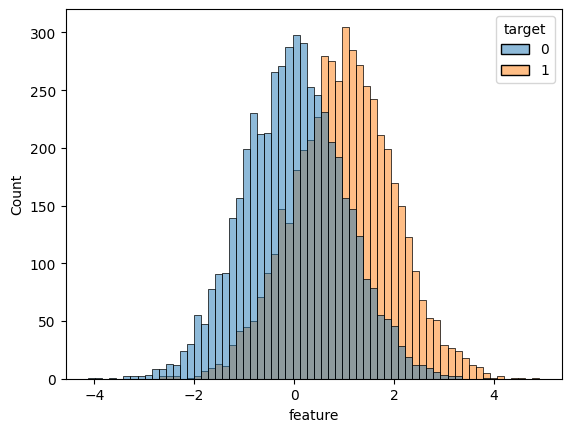

In [ ]:
sns.histplot(df, x = 'feature', hue = 'target')

In [ ]:
# запустите после того, как реализуете все функции
woe_line(values=x, target=y, n_buckets=5)

### Эксперименты (2 балла)

#### №1

Как будут меняться график, метрики разделяющей способности и $R^2$ при изменении дисперсии шума (параметр `noise_std`)?

При увеличении шума метрики падают так как линейность пропадает с ним. И наоборот. Ниже вижно что график с увелечением шума начинает осциллировать.

In [ ]:
for noise_std in [0.5, 1.0, 3.0]:
    np.random.seed(89)
    x = np.concatenate([
        sps.norm(0, noise_std).rvs(size=sample_size // 2),
        sps.norm(1, noise_std).rvs(size=sample_size // 2)
    ])

    fig = woe_line(x, y, n_buckets=10)
    fig.show()

#### №2

Запустите функцию с `values=x ** 2`. Как по графику определить эту ситуацию? Что нужно делать в таком случае?

Пропадает линейность и отрицательные значения. Исправить можно посмотрев на график наш и попробовать понять как вернуть знак и взять корень.

In [ ]:
x = np.concatenate([
    sps.norm(0, noise_std).rvs(size=sample_size // 2),
    sps.norm(1, noise_std).rvs(size=sample_size // 2)
])

values = x ** 2

fig = woe_line(values, y, n_buckets=10)
fig.show()

#### №3

Запустите функцию с `values=np.exp(x)`. Как по графику определить эту ситуацию? Что нужно делать в таком случае?

Быстро растет по X. r2 низкий так как опять же нет линейности. Исправить логарифмом.

In [ ]:
values = np.exp(x)

fig = woe_line(values, y, n_buckets=10)
fig.show()

## Часть 2. Строим ЛогРег. (8 баллов)

В этом пунтке попробуем применить все наши навыки

Скачайте датасет на EDU. Пароль вы найдете в телеграм-канале курса, в посте с анонсом домашки.

In [ ]:
df = pd.read_csv('logreg_hw_5.csv', index_col=0)
df

,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11,feature_12,feature_13,feature_14,feature_15,d4p12
0,-1.444709,3.554779,1.308371,-0.000119,0.029628,3.829880,1,8.825418,3.829880,11.565953,-513.014565,-1.072893,7.936545,0.047069,B,1
1,1.132531,-0.207661,-2.142882,0.062686,0.859062,6.189545,1,3.453220,6.189545,4.935665,-39.351891,3.409855,17.015210,0.029288,A,0
2,1.268781,-0.243999,10000.000000,0.339225,0.614599,12.503629,1,-10.116061,12.503629,6.234414,-4.993050,3.121126,4.878602,0.237255,A,0
3,-1.278475,-2.579890,5.050763,-0.938956,0.090461,-1.080041,1,6.780814,-1.080041,2.682539,-509.273095,-1.242741,20.293025,0.907788,B,0
4,3.507807,0.152661,-8.905005,0.067646,0.216199,1.367184,1,-10.638134,1.367184,6.881602,-2.034797,2.814972,7.352399,0.276854,A,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,-3.061422,-0.163832,4.812768,-0.949937,0.224437,5.263508,1,-9.959913,5.263508,5.294558,-524.265291,-1.648415,5.410059,0.855190,B,0
99996,0.222451,-0.273191,0.380895,0.860607,0.950708,0.581767,1,-1.645952,0.581767,5.571499,-13.499956,3.386865,92.903615,0.006668,A,1
99997,1.078498,0.339526,-5.184847,0.242072,0.854085,0.995075,1,-5.565932,0.995075,-0.433263,3.928387,3.290285,1.233853,0.160933,A,1
99998,-1.431421,-0.605388,2.466023,-0.056519,0.736255,2.980562,1,-4.517188,2.980562,10.812813,-507.593408,-1.398568,1904.246147,0.077164,B,1


Как вы выдите, ```feature_1, ..., feature_14``` - числа
```feature_15``` - категориальная фича

### Задание 0. EDA.

Как бы вы начали знакомиться с данными до построения модели? Постройте 3-5 графиков / таблиц, чтобы передать основную информацию о датасете.

In [ ]:
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
num_cols = df.select_dtypes(exclude=['object']).columns.tolist()
num_cols.remove('d4p12')

print(cat_cols)
print(num_cols)

df.describe().T

['feature_15']
['feature_1', 'feature_2', 'feature_3', 'feature_4', 'feature_5', 'feature_6', 'feature_7', 'feature_8', 'feature_9', 'feature_10', 'feature_11', 'feature_12', 'feature_13', 'feature_14']


,count,mean,std,min,25%,50%,75%,max
feature_1,100000.0,-0.004065,2.625003,-5.459815e+01,-1.011666,-5.840572e-02,1.004057,39.011329
feature_2,100000.0,-0.198827,169.576125,-3.829617e+04,-0.385200,-7.289443e-02,0.395806,20133.753873
feature_3,100000.0,-6.283870,2344.152317,-1.000000e+04,-4.215224,3.199660e-03,4.255211,10000.000000
feature_4,100000.0,-0.125161,0.590046,-1.999985e+00,-0.221922,-2.735552e-09,0.109650,0.999952
feature_5,100000.0,1.001067,1.003677,9.339844e-06,0.287134,6.945427e-01,1.383918,11.629614
feature_6,100000.0,2.990486,3.997014,-1.873238e+01,0.288999,3.001134e+00,5.688353,21.549778
feature_7,100000.0,0.900280,0.299628,0.000000e+00,1.000000,1.000000e+00,1.000000,1.000000
feature_8,100000.0,-2.514795,5.009291,-2.649654e+01,-5.893561,-2.511154e+00,0.859395,19.258719
feature_9,100000.0,2.990486,3.997014,-1.873238e+01,0.288999,3.001134e+00,5.688353,21.549778
feature_10,100000.0,3.640370,4.977886,-1.684703e+01,0.270052,3.669848e+00,6.984301,24.764462


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 100000 entries, 0 to 99999
Data columns (total 16 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   feature_1   100000 non-null  float64
 1   feature_2   100000 non-null  float64
 2   feature_3   100000 non-null  float64
 3   feature_4   100000 non-null  float64
 4   feature_5   100000 non-null  float64
 5   feature_6   100000 non-null  float64
 6   feature_7   100000 non-null  int64  
 7   feature_8   100000 non-null  float64
 8   feature_9   100000 non-null  float64
 9   feature_10  100000 non-null  float64
 10  feature_11  100000 non-null  float64
 11  feature_12  100000 non-null  float64
 12  feature_13  100000 non-null  float64
 13  feature_14  100000 non-null  float64
 14  feature_15  100000 non-null  object 
 15  d4p12       100000 non-null  int64  
dtypes: float64(13), int64(2), object(1)
memory usage: 13.0+ MB


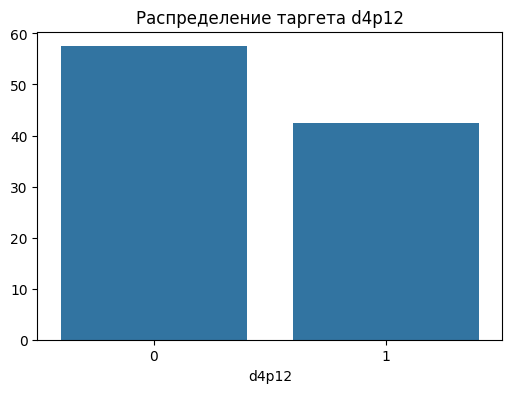

In [ ]:
import matplotlib.pyplot as plt


plt.figure(figsize=(6, 4))

target_counts = df["d4p12"].value_counts(normalize=True) * 100
ax = sns.barplot(x=target_counts.index, y=target_counts.values)
plt.title(f'Распределение таргета {target_col}')

plt.show()

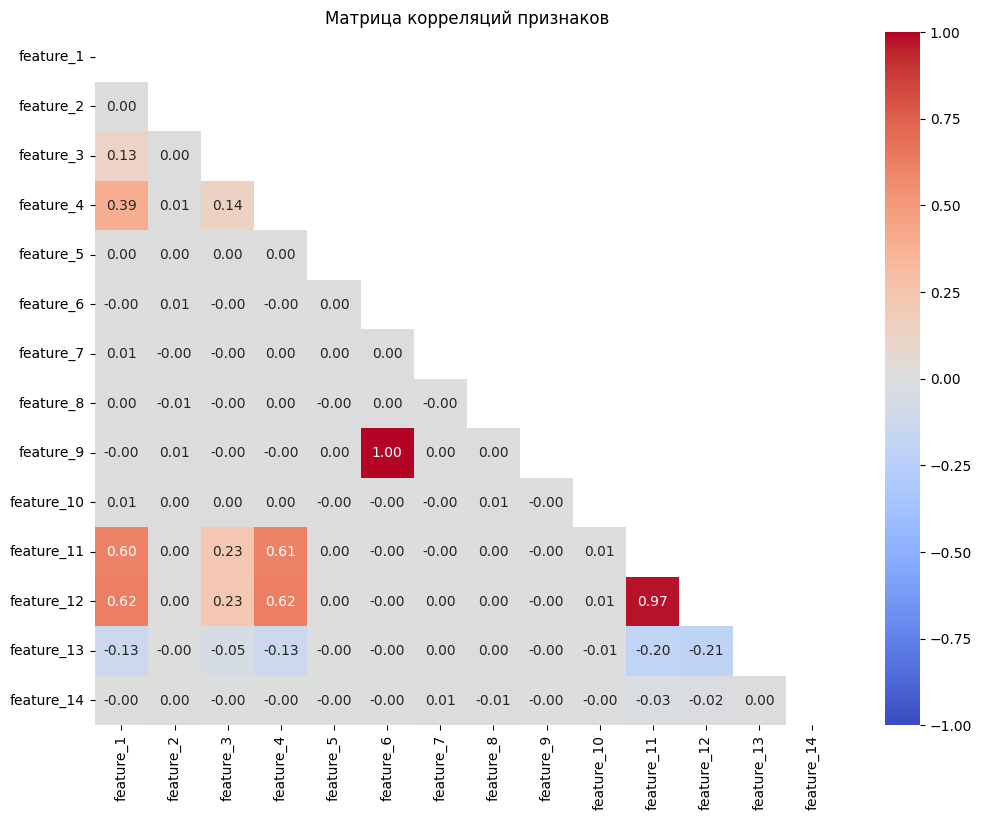

In [ ]:
plt.figure(figsize=(12, 9))
corr_matrix = df[num_cols].corr()


mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1)
plt.title('Матрица корреляций признаков')
plt.show()

Найденные категориальные колонки: ['feature_15']


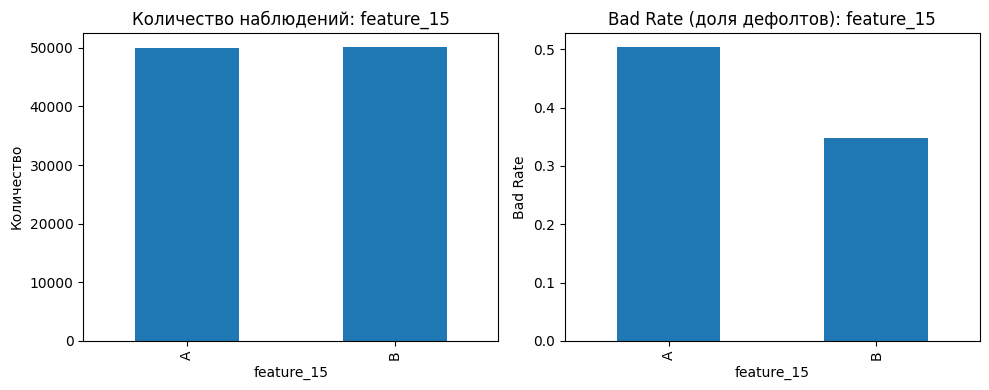

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
print("Найденные категориальные колонки:", cat_cols)

cat_col = cat_cols[0]
target_col = 'd4p12'

cat_stats = df.groupby(cat_col, observed=False)[target_col].agg(
    count='count',
    bad_rate='mean'
)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

cat_stats['count'].plot(kind='bar', ax=axes[0])
axes[0].set_title(f'Количество наблюдений: {cat_col}')
axes[0].set_ylabel('Количество')

cat_stats['bad_rate'].plot(kind='bar', ax=axes[1])
axes[1].set_title(f'Bad Rate (доля дефолтов): {cat_col}')
axes[1].set_ylabel('Bad Rate')

plt.tight_layout()
plt.show()

/tmp/ipykernel_1016/3964299862.py:6: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_1016/3964299862.py:6: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_1016/3964299862.py:6: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_1016/3964299862.py:6: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_1016/3964299862.py:6: FutureWarning:



Passing `palette` without assigning `hue` is deprecated a

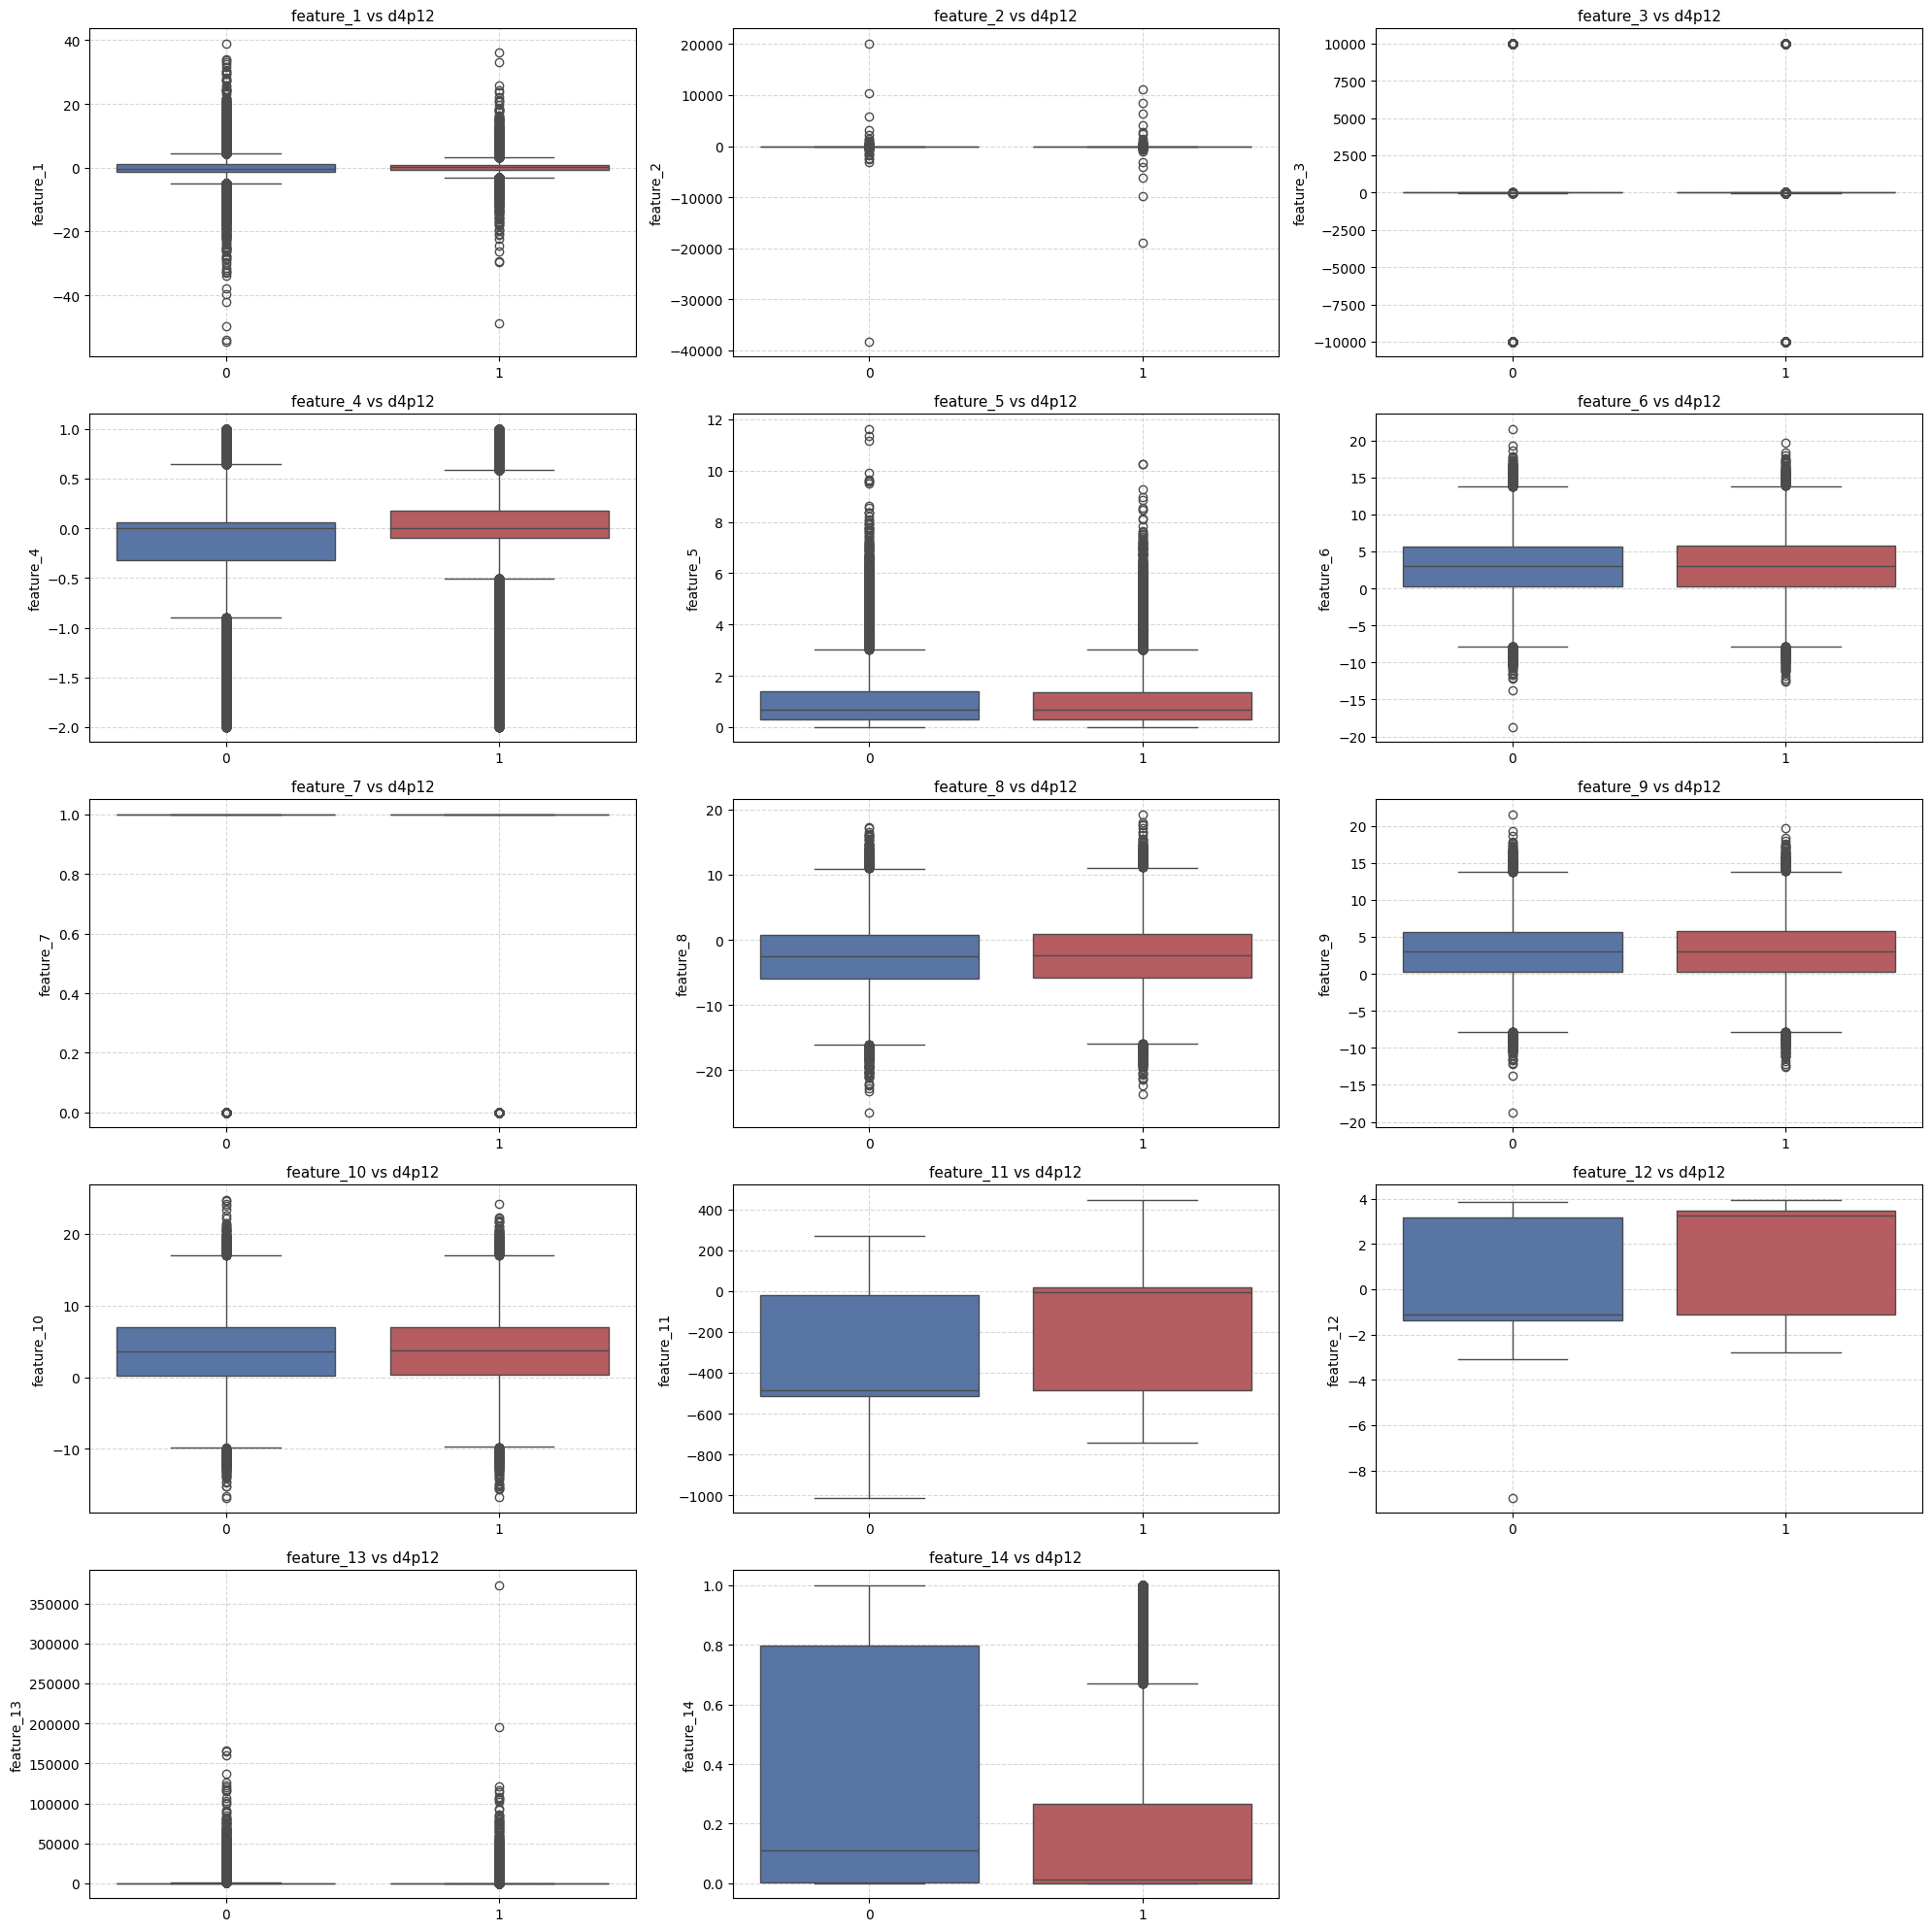

In [ ]:
sample_features = num_cols

plt.figure(figsize=(20, 20))
for i, col in enumerate(sample_features, 1):
    plt.subplot(5, 3, i)
    sns.boxplot(x=target_col, y=col, data=df, palette=['#4C72B0', '#C44E52'], showfliers=True)
    plt.title(f'{col} vs {target_col}', fontsize=11)
    plt.xlabel('')
    plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Задание 1. Бейзлайн.

Попробуйте построить ЛогРег только на числовых данных. Для этого разбейте датасет на трейн и тест (80/20). Перед обучением логрега стандартизуйте переменные. Это может быть полезно для численной устойчивости алгоритмов оптимизации.

Для этой модели и всех дальнейших:

1. Получилась ли модель линейной? Постройте график линейности на трейне и на тесте и сделайте вывод.
2. Расчитайте AUC и IV на трейне и на тесте. Что можно сказать о переобучении?

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

In [ ]:
target_col = 'd4p12'

num_cols = df.select_dtypes(include=[np.number]).drop(columns=[target_col]).columns.tolist()
cat_cols = df.select_dtypes(include=['object']).columns.tolist()

X = df[num_cols]
y = df[target_col].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression(random_state=42, max_iter=1000)
model.fit(X_train_scaled, y_train)

train_scores = model.decision_function(X_train_scaled)
test_scores = model.decision_function(X_test_scaled)

print("--- График линейности модели на Train ---")
fig_train = woe_line(train_scores, y_train, n_buckets=10)
fig_train.show()

print("--- График линейности модели на Test ---")
fig_test = woe_line(test_scores, y_test, n_buckets=10)
fig_test.show()

--- График линейности модели на Train ---


--- График линейности модели на Test ---


### Задание 2. Добавляем категориальную переменную.

Повторите задание 1, включив в модель категориальную переменную (например, с помощью one-hot encoding).

Улучшилось ли качество?

In [ ]:
X = df[num_cols + cat_cols]
y = df[target_col].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), cat_cols)
    ]
)

X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)

model_cat = LogisticRegression(random_state=42, max_iter=1000)
model_cat.fit(X_train_proc, y_train)

train_scores_cat = model_cat.decision_function(X_train_proc)
test_scores_cat = model_cat.decision_function(X_test_proc)

print("--- График линейности модели с категориальным признаком (Train) ---")
fig_train_cat = woe_line(train_scores_cat, y_train, n_buckets=10)
fig_train_cat.show()

print("--- График линейности модели с категориальным признаком (Test) ---")
fig_test_cat = woe_line(test_scores_cat, y_test, n_buckets=10)
fig_test_cat.show()

--- График линейности модели с категориальным признаком (Train) ---


--- График линейности модели с категориальным признаком (Test) ---


### Задание 3. Линеаризация переменных.

На самом деле, категориальные переменные можно учитывать в моделях совсем по-другому. С их помощью можно выделить в модели сегменты. Каждому сегменту соответствует своя модель (в нашем случае логрег).

Примером такой сегментации может стать сегментация по наличию кредитной истории. В этом случае на разных сегментах будут не просто отдельные модели, но и даже разный изначальный набор признаков. Другое свидетельство удачной сегментации – разный характер зависимости признаков и целевой переменной. Это можно увидеть на графике линейности признака по WoE. Этим мы и займемся далее.

Используйте переменную 15 для сегментации модели. На каждом из двух сегментов линеаризуйте переменные. Для этого приложите:
 - график линейности переменной до преобразования
 - график после подобранного преобразования

Помимо этого:
 - попробуйте линеаризовать какие-нибудь 2 переменные *на всей выборке*. Получилось ли у вас что-то? Постройте график.
 - по графику линейности определите шумовые (либо слабоинформативные) переменные. В конце задания приложите их список.

In [ ]:
def compare_transformation(df_sub, feature_name, transform_func, transform_label="Трансформация"):
    """Отрисовывает графики линейности до и после применения трансформации."""
    y = df_sub[target_col].values
    val_orig = df_sub[feature_name].values

    print(f"=== {feature_name} ДО преобразования ===")
    fig_before = woe_line(val_orig, y, n_buckets=10)
    fig_before.show()

    val_trans = transform_func(val_orig)
    print(f"=== {feature_name} ПОСЛЕ ({transform_label}) ===")
    fig_after = woe_line(val_trans, y, n_buckets=10)
    fig_after.show()

In [ ]:
cat_col = cat_cols[0]

categories = df[cat_col].unique()
seg_A_name, seg_B_name = categories[0], categories[1]

df_seg_A = df[df[cat_col] == seg_A_name].copy()
df_seg_B = df[df[cat_col] == seg_B_name].copy()

print(f"Сегмент {seg_A_name}: {df_seg_A.shape[0]} строк")
print(f"Сегмент {seg_B_name}: {df_seg_B.shape[0]} строк")

Сегмент B: 50106 строк
Сегмент A: 49894 строк


In [ ]:
feature_name = "feature_2"
y = df_seg_A[target_col].values
x = df_seg_A[feature_name].values

low_val = np.percentile(x, 1)
high_val = np.percentile(x, 99)
vals = np.clip(x, low_val, high_val)

print(f"=== {feature_name} ДО преобразования ===")
fig = woe_line(vals, y, n_buckets=10)
fig.show()

y = df_seg_B[target_col].values
vals = df_seg_B[feature_name].values

print(f"=== {feature_name} ДО преобразования ===")
fig = woe_line(vals, y, n_buckets=10)
fig.show()

=== feature_2 ДО преобразования ===


=== feature_2 ДО преобразования ===


In [ ]:
fun_A_feature_1 = lambda x: np.exp(x)
name = "feature_1"
compare_transformation(df_seg_A, name, fun_A_feature_1)

low_val = np.percentile(x, 1)
high_val = np.percentile(x, 95)
fun_B_feature_1 = lambda x: np.clip(x,low_val, high_val)
compare_transformation(df_seg_B, name, fun_B_feature_1)


=== feature_1 ДО преобразования ===


=== feature_1 ПОСЛЕ (Трансформация) ===


=== feature_1 ДО преобразования ===


=== feature_1 ПОСЛЕ (Трансформация) ===


In [ ]:
low_val = np.percentile(x, 1)
high_val = np.percentile(x, 99)
x_clipped = np.clip(x, low_val, high_val)

fun_A_feature_1 = lambda x: np.clip(x, low_val, high_val)
name = "feature_3"
compare_transformation(df_seg_A, name, fun_A_feature_1)

fun_B_feature_1 = lambda x: np.clip(x, low_val, high_val)
compare_transformation(df_seg_B, name, fun_B_feature_1)


=== feature_3 ДО преобразования ===


=== feature_3 ПОСЛЕ (Трансформация) ===


=== feature_3 ДО преобразования ===


=== feature_3 ПОСЛЕ (Трансформация) ===


### Задание 4. Финальная модель.

Обучите модели на признаках, которые вы отобрали и линеаризовали в задании 3. Пусть $logit_A$ – модель, обученная на сегменте $feature_{15} = A$. $logit_B$ – модель на втором сегменте. Тогда модель на всей выборке будем считать по формуле

$$
logit(x) = \mathbb I \{ feature_{15} = A \} \times logit_A(x) + \mathbb I \{ feature_{15} = B \} \times logit_B(x)
$$


Посчитайте для этой модели AUC и IV, оцените линейность на трейне и тесте. Сравните результаты с бейзлайном из задания 1.

Подсказка: если вы все сделали правильно, можно ожидать ROC AUC около 0.9 на тестовой выборке.

In [ ]:
df = pd.read_csv("logreg_hw_5.csv", index_col=0)


In [ ]:
target_col = 'd4p12'
cat_col = df.select_dtypes(include=['object', 'category']).columns[0] # feature_15

train_df, test_df = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df[target_col]
)

def prepare_segment_A(data):
    res = data.copy()
    low_val = np.percentile(x, 1)
    high_val = np.percentile(x, 99)

    res['feature_1'] = np.exp(res['feature_1'])
    res['feature_3'] = np.clip(res['feature_3'], low_val, high_val)

    feature_cols = [c for c in res.columns if c not in [target_col, cat_col]]
    return res[feature_cols]

def prepare_segment_B(data):
    res = data.copy()
    low_val = np.percentile(x, 1)
    high_val = np.percentile(x, 99)
    low_val_1 = np.percentile(x, 1)
    high_val_1 = np.percentile(x, 95)

    res['feature_1'] = np.clip(res['feature_1'] ,low_val_1, high_val_1)
    res['feature_3'] = np.clip(res['feature_3'], low_val, high_val)

    feature_cols = [c for c in res.columns if c not in [target_col, cat_col]]
    return res[feature_cols]

In [ ]:
categories = sorted(df[cat_col].unique())
cat_A_val, cat_B_val = categories[0], categories[1]

train_A = train_df[train_df[cat_col] == cat_A_val]
test_A = test_df[test_df[cat_col] == cat_A_val]

X_train_A = prepare_segment_A(train_A)
y_train_A = train_A[target_col].values
X_test_A = prepare_segment_A(test_A)
y_test_A = test_A[target_col].values

scaler_A = StandardScaler()
X_train_A_scaled = scaler_A.fit_transform(X_train_A)
X_test_A_scaled = scaler_A.transform(X_test_A)

model_A = LogisticRegression(random_state=42, max_iter=1000)
model_A.fit(X_train_A_scaled, y_train_A)

train_logits_A = model_A.decision_function(X_train_A_scaled)
test_logits_A = model_A.decision_function(X_test_A_scaled)

train_B = train_df[train_df[cat_col] == cat_B_val]
test_B = test_df[test_df[cat_col] == cat_B_val]

X_train_B = prepare_segment_B(train_B)
y_train_B = train_B[target_col].values
X_test_B = prepare_segment_B(test_B)
y_test_B = test_B[target_col].values

scaler_B = StandardScaler()
X_train_B_scaled = scaler_B.fit_transform(X_train_B)
X_test_B_scaled = scaler_B.transform(X_test_B)

model_B = LogisticRegression(random_state=42, max_iter=1000)
model_B.fit(X_train_B_scaled, y_train_B)

train_logits_B = model_B.decision_function(X_train_B_scaled)
test_logits_B = model_B.decision_function(X_test_B_scaled)


train_logits_total = np.zeros(len(train_df))
mask_train_A = (train_df[cat_col] == cat_A_val).values
mask_train_B = (train_df[cat_col] == cat_B_val).values
train_logits_total[mask_train_A] = train_logits_A
train_logits_total[mask_train_B] = train_logits_B
y_train_total = train_df[target_col].values

test_logits_total = np.zeros(len(test_df))
mask_test_A = (test_df[cat_col] == cat_A_val).values
mask_test_B = (test_df[cat_col] == cat_B_val).values
test_logits_total[mask_test_A] = test_logits_A
test_logits_total[mask_test_B] = test_logits_B
y_test_total = test_df[target_col].values

In [ ]:
print("--- Финальная сегментированная модель (Train) ---")
fig_final_train = woe_line(train_logits_total, y_train_total, n_buckets=10)
fig_final_train.show()

print("--- Финальная сегментированная модель (Test) ---")
fig_final_test = woe_line(test_logits_total, y_test_total, n_buckets=10)
fig_final_test.show()

--- Финальная сегментированная модель (Train) ---


--- Финальная сегментированная модель (Test) ---


# Часть 3. Бонус. (3 балла)

На лекции мы накопили ряд упражнений, которые стоит решить для понимания происходившего. Вы можете $\TeX$ать их прямо в ноуте (или прикреплять картинки, если так удобнее).

#### **Упражнение 1**

Для определения $WoE$ мы пользовались Теоремой Байеса. Примените ее и **покажите, что верно равенство**:

$$
\ln \left(  \frac{P(x_i|y=1)}{P(x_i|y=0)} \right) = ... = \ln \left( \frac{P(y=1|x_i)}{P(y=0|x_i)} \right) - \ln \left( \frac{P(y=1)}{P(y=0)} \right)
$$

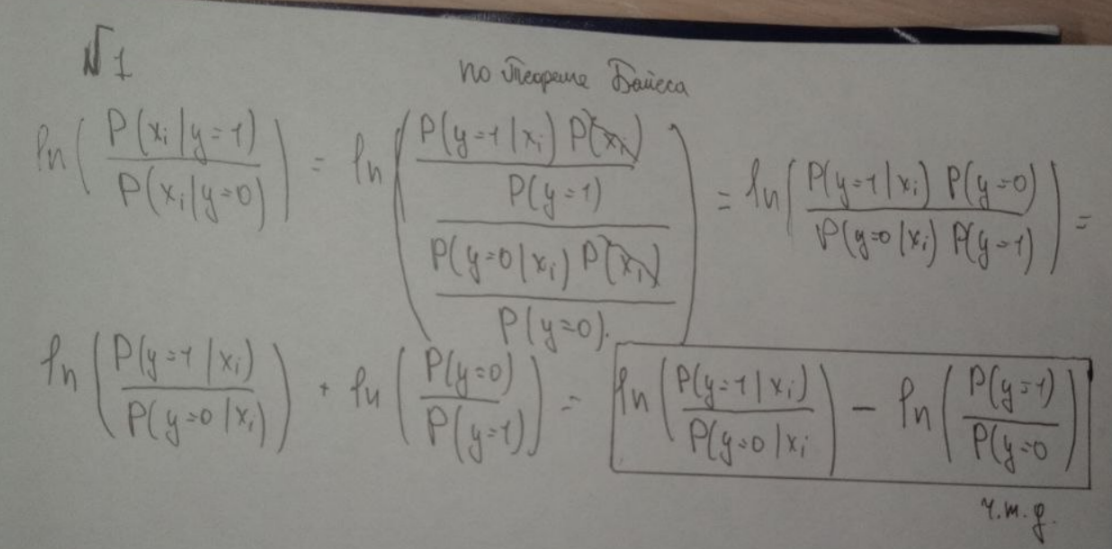

#### **Упражнение 2**

Известно:

$WoE$ можно посчитать так:
$WoE_i(x_i) = \ln \Big ( \frac{B_i}{G_i} \Big ) - \ln \Big ( \frac{B}{G} \Big ) $

Частота выхода в дефолт:  $badrate = \frac{B}{B+G}; \quad badrate_i = \frac{B_i}{B_i+G_i}$

$
\sigma (x) = \frac{1}{1+e^{-x}}; \quad logit(x) = \ln \left( \frac{x}{1-x} \right)
$

**Покажите, что**
$WoE_i(x_i) = logit(badrate_i) - logit(badrate)$

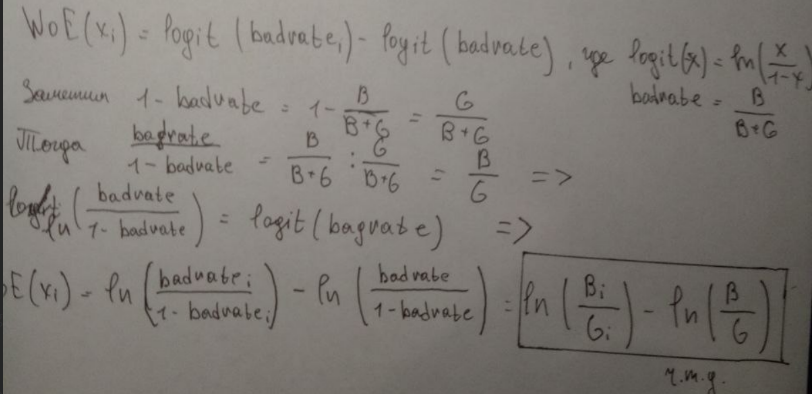

#### **Упражнение 3**

Пусть даны два дискретных распределения:

$B=(b_1, ..., b_n)$ и $G=(g_1, ..., g_n)$.

KL-дивергенция для дискретных распределений

$$D_{KL}(B||G) = \sum_{j=1}^{n} b_j \ln \left( \frac{b_j}{g_j} \right)$$


Пусть $x$ - дикретный признак, принмиающий значения $x_1,...,x_n$.
Известно определение IV через KL-дивергенцию:

$$
IV_x = D_{KL}(B_x||G_x)+D_{KL}(G_x||B_x)
$$
где

$$
B_x (x_i) = P(x=x_i|y=1) = b_i; \quad G_x (x_i) = P(x=x_i|y=0) = g_i
$$

**Выразите $IV$ через $WoE$**





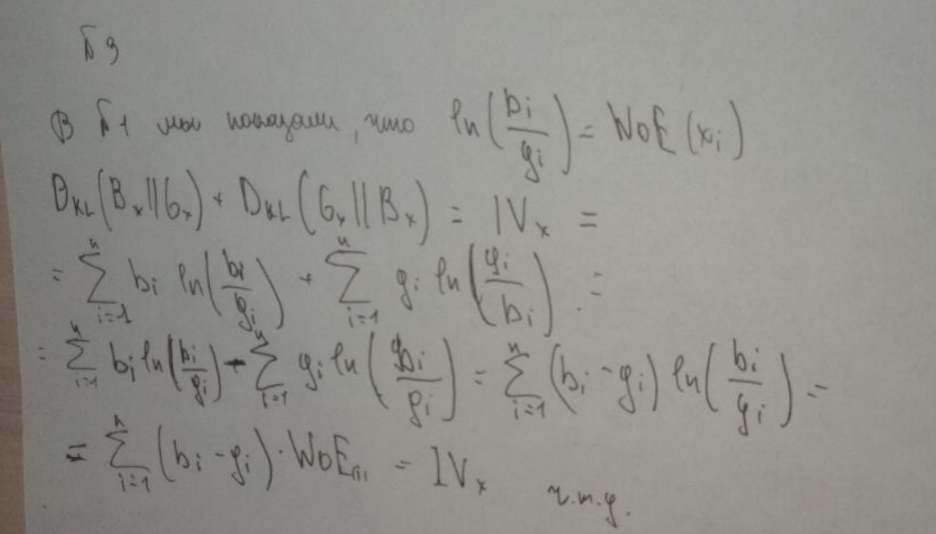